# 01 — First look at one session

**Goal of the project.** We want a reliable breathing signal for a mouse. Three sensors record breathing at the same time, and each fails in a different way:

| Sensor | What it measures | Strength | Weakness |
|---|---|---|---|
| **Thermistor** | air temperature just outside the nose (cool = inhale, warm = exhale) | smooth, clean | slow; disturbed when the head moves |
| **Airflow** | air moving through the nose | most direct | noisy, sharp spikes |
| **LFP** | electrical activity in the olfactory epithelium (inside the nose) | implanted, so stable during movement | indirect |

The long-term plan is to combine them so that when one sensor fails, the other two fill the gap.

**This notebook** loads one recording, plots the sensors, converts each one to a *breathing phase*, and measures how well the sensors agree over time.

Run cells top to bottom with **Shift+Enter**.

## 1. Setup

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path

DATA = Path("data/2026-06-18_16-25-09_000/alf")   # folder with the .npy files
FS = 1000                                          # samples per second (from the README)

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"Thermistor": "#2a78d6", "Airflow": "#eb6834", "LFP": "#1baf7a"}

# below are helper functions that were involved in desicion making in this notebook

# ---- Helper functions (explained in sections 6 and 7; used earlier as black boxes) ----
def bandpass(x, lo, hi, order=3):
    b, a = signal.butter(order, [lo, hi], btype="band", fs=FS)
    return signal.filtfilt(b, a, x, axis=0)          # axis=0: filter along time (also works for multi-channel LFP)

def get_phase(x, lo=1, hi=15):
    return np.angle(signal.hilbert(bandpass(x, lo, hi), axis=0))

def sliding_plv(p1, p2, win_s=5, step_s=1):
    # returns window CENTER times (s) and the PLV of each window
    W, S = int(win_s * FS), int(step_s * FS)
    starts = np.arange(0, len(p1) - W, S)
    vals = np.array([np.abs(np.mean(np.exp(1j * (p1[s:s+W] - p2[s:s+W])))) for s in starts])
    return (starts + W / 2) / FS, vals

def smooth(x, win_s):
    W = int(win_s * FS)
    return np.convolve(x, np.ones(W) / W, mode="same")

## 2. What's in the folder

Each `.npy` file is one NumPy array. Printing shapes is always the first check: the time dimension (number of samples) should match across signals.

In [16]:
for f in sorted(DATA.glob("*.npy")):
    a = np.load(f)
    print(f"{f.name:35s} shape={str(a.shape):16s} dtype={a.dtype}")

_cavelli_airflow.signal.npy         shape=(397714,)        dtype=float32
_cavelli_chest.signal.npy           shape=(397714,)        dtype=float32
_cavelli_ekg.signal.npy             shape=(397714, 2)      dtype=float32
_cavelli_emg.signal.npy             shape=(397714, 2)      dtype=float32
_cavelli_lfp.signal.npy             shape=(397714, 10)     dtype=float32
_cavelli_thermistor.signal.npy      shape=(397714,)        dtype=float32
ephys.nSamples.npy                  shape=()               dtype=int64
ephys.samplingRate.npy              shape=()               dtype=float32
ephys.timestamps.npy                shape=(397714,)        dtype=float64
leftCamera.times.npy                shape=(22217,)         dtype=float64
rightCamera.times.npy               shape=(22217,)         dtype=float64


In [17]:
thermistor = np.load(DATA / "_cavelli_thermistor.signal.npy").astype(float)
airflow    = np.load(DATA / "_cavelli_airflow.signal.npy").astype(float)
chest      = np.load(DATA / "_cavelli_chest.signal.npy").astype(float)
lfp_all    = np.load(DATA / "_cavelli_lfp.signal.npy").astype(float)   # (samples, 10 channels)
emg        = np.load(DATA / "_cavelli_emg.signal.npy").astype(float)[:, 0]
cam_times  = np.load(DATA / "leftCamera.times.npy")

t = np.arange(len(thermistor)) / FS            # time axis in seconds
print(f"Recording length: {t[-1]:.1f} s ({t[-1]/60:.1f} min)")
print("Chest sensor non-zero samples:", np.count_nonzero(chest), "-> not recorded in this session")
print(f"Video: {len(cam_times)} frames, {cam_times[0]:.1f}-{cam_times[-1]:.1f} s, "
      f"~{1/np.median(np.diff(cam_times)):.1f} fps, largest frame gap {np.diff(cam_times).max()*1000:.1f} ms")

Recording length: 397.7 s (6.6 min)
Chest sensor non-zero samples: 0 -> not recorded in this session
Video: 22217 frames, 17.7-388.0 s, ~60.0 fps, largest frame gap 16.7 ms


## 3. Which LFP channel to use?

The LFP has 10 channels. The correlation matrix shows they form a gradient: neighbors are nearly identical, and the two ends (channels 0–3 vs 7–9) have *opposite* sign. For now we use **channel 0**.

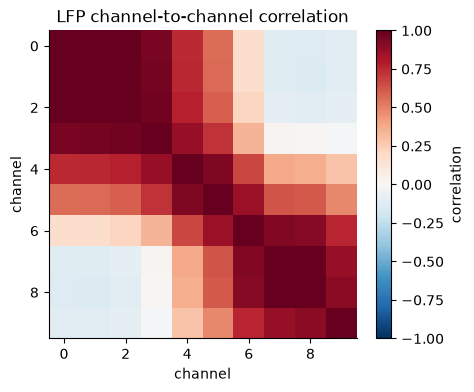

In [18]:
corr = np.corrcoef(lfp_all.T)
plt.figure(figsize=(5, 4))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation"); plt.xlabel("channel"); plt.ylabel("channel")
plt.title("LFP channel-to-channel correlation"); plt.grid(False); plt.show()

lfp = lfp_all[:, 0]

The version above uses raw LFP signals, below the matrix is filtered to the breathing band (1-15Hz)

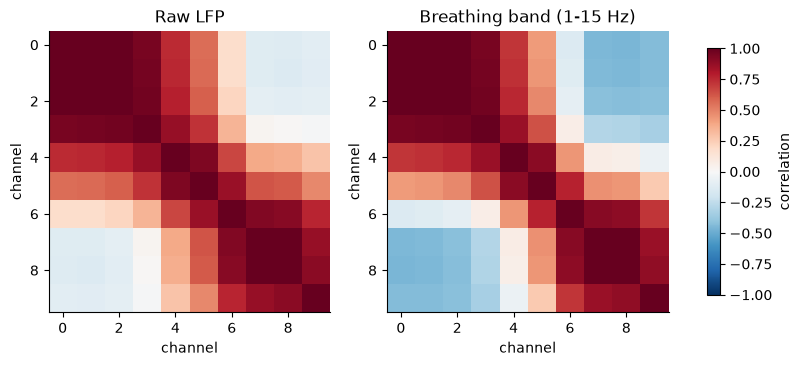

channel 0 vs:       0      1      2      3      4      5      6      7      8      9
raw             1.00   1.00   0.99   0.95   0.75   0.56   0.18  -0.12  -0.13  -0.10
breathing band  1.00   1.00   1.00   0.95   0.71   0.43  -0.13  -0.45  -0.46  -0.44


In [19]:
# Filter every LFP channel to the breathing band (1-15 Hz)
# axis=0 means "filter along time", so all 10 channels are filtered at once
b, a = signal.butter(3, [1, 15], btype="band", fs=FS)
lfp_breath = signal.filtfilt(b, a, lfp_all, axis=0)

# Correlation of every channel with every other channel, after filtering
corr_breath = np.corrcoef(lfp_breath.T)

# Plot raw vs breathing band side by side, on the same color scale
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, matrix, title in [(axes[0], corr, "Raw LFP"),
                          (axes[1], corr_breath, "Breathing band (1-15 Hz)")]:
    im = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.set_xlabel("channel")
    ax.set_ylabel("channel")
    ax.grid(False)
fig.colorbar(im, ax=axes, label="correlation", shrink=0.8)
plt.show()

# Channel 0 compared with every channel, raw vs filtered
print("channel 0 vs:   " + "  ".join(f"{i:>5d}" for i in range(10)))
print("raw            " + "  ".join(f"{v:5.2f}" for v in corr[0]))
print("breathing band " + "  ".join(f"{v:5.2f}" for v in corr_breath[0]))

### 3c. Testing the channel choice

The correlation matrix shows which channels resemble each other, not which ones track breathing. To choose, compare each channel's breathing phase with the two direct breathing sensors. A good channel should agree well with both.

This uses phase and the agreement score (PLV), explained in sections 6–7. For now, treat PLV as a score from 0 (unrelated) to 1 (perfectly in step).

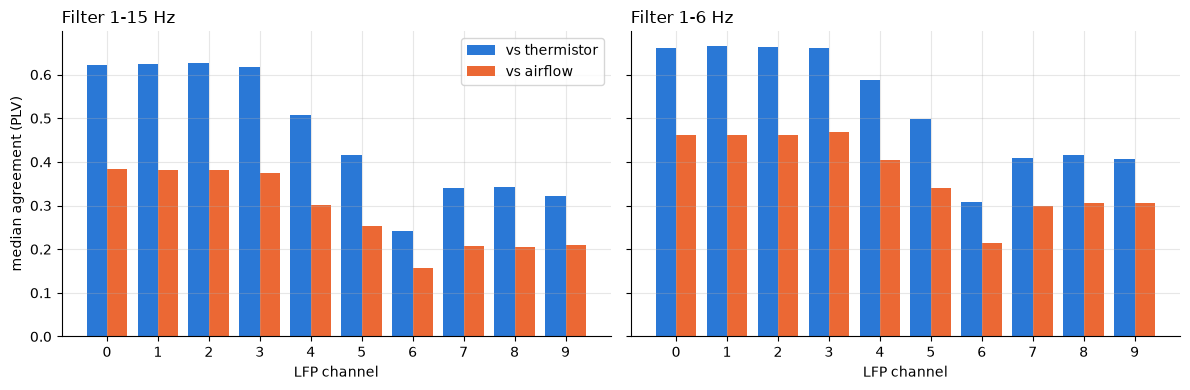

1-15 Hz  vs thermistor: 0.622 0.624 0.627 0.616 0.506 0.415 0.242 0.340 0.343 0.321
1-15 Hz  vs airflow:    0.384 0.382 0.381 0.376 0.301 0.253 0.156 0.206 0.206 0.210
1-6 Hz  vs thermistor: 0.660 0.666 0.664 0.661 0.587 0.498 0.308 0.409 0.416 0.407
1-6 Hz  vs airflow:    0.461 0.462 0.462 0.468 0.404 0.340 0.213 0.300 0.306 0.306


In [20]:
bands_tested = [(1, 15), (1, 6)]
results = {}
for band in bands_tested:
    p_th_b  = get_phase(thermistor, *band)
    p_af_b  = get_phase(airflow, *band)
    p_lfp_b = get_phase(lfp_all, *band)                 # all 10 channels at once
    results[band] = {
        "vs thermistor": [np.median(sliding_plv(p_lfp_b[:, c], p_th_b)[1]) for c in range(10)],
        "vs airflow":    [np.median(sliding_plv(p_lfp_b[:, c], p_af_b)[1]) for c in range(10)],
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
x = np.arange(10)
for ax, band in zip(axes, bands_tested):
    ax.bar(x - 0.2, results[band]["vs thermistor"], 0.4, color=COLORS["Thermistor"], label="vs thermistor")
    ax.bar(x + 0.2, results[band]["vs airflow"],    0.4, color=COLORS["Airflow"],    label="vs airflow")
    ax.set_xticks(x); ax.set_xlabel("LFP channel"); ax.set_title(f"Filter {band[0]}-{band[1]} Hz", loc="left")
axes[0].set_ylabel("median agreement (PLV)"); axes[0].legend()
plt.tight_layout(); plt.show()

for band in bands_tested:
    print(f"{band[0]}-{band[1]} Hz  vs thermistor:", " ".join(f"{v:.3f}" for v in results[band]["vs thermistor"]))
    print(f"{band[0]}-{band[1]} Hz  vs airflow:   ", " ".join(f"{v:.3f}" for v in results[band]["vs airflow"]))

lfp = lfp_all[:, 0]      # the choice: channel 0 (see result below)

Channels 0-3 exhibits strong agreement with the thermistor and airflow. So we pick channel 0 out of default. 

## 4. Look at the raw signals

The sensors have different units, so we **z-score** each one (subtract the mean, divide by the standard deviation) and stack them. Change `start` to look at other parts of the recording.

Graph over entire timeline. This may be difficult to read given the frequency of breaths. So we zoom in on interesting parts. 

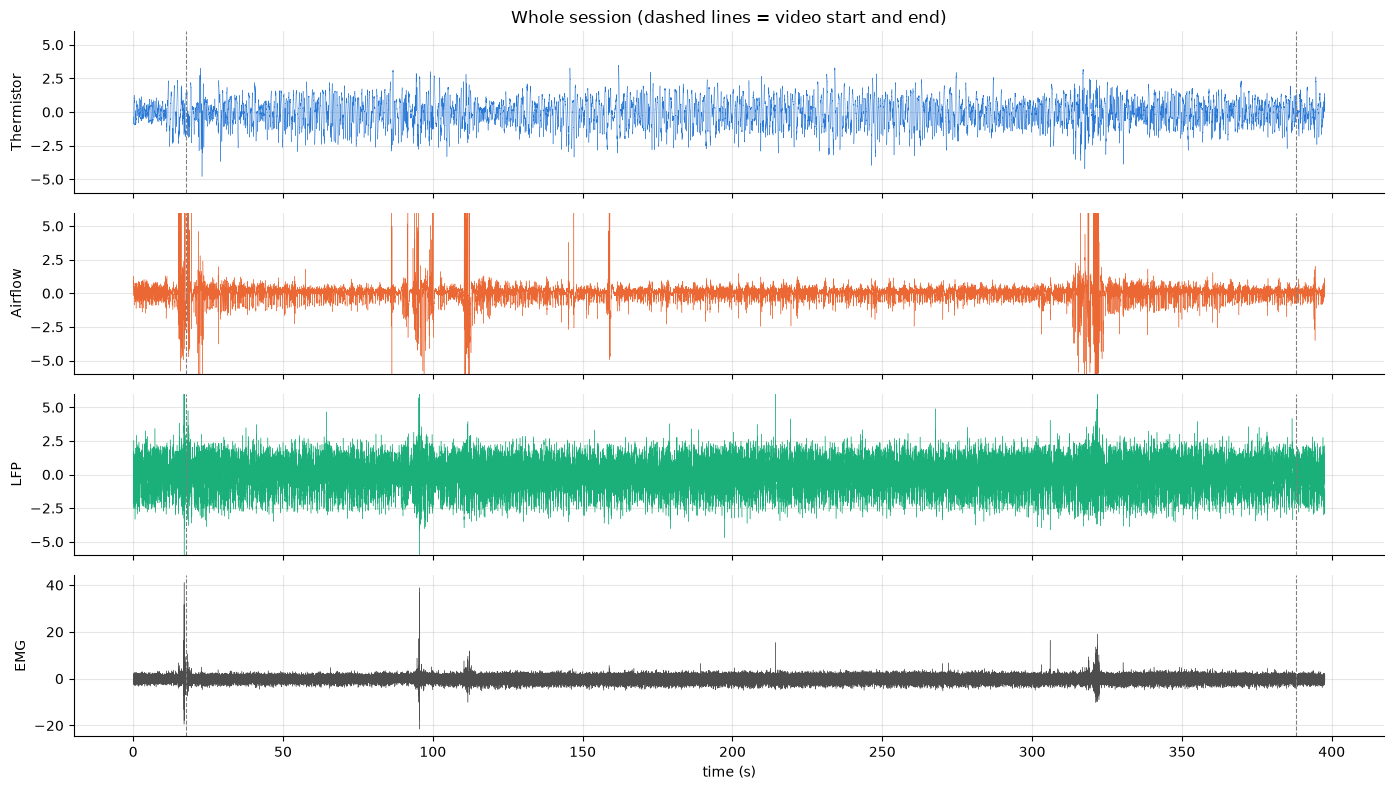

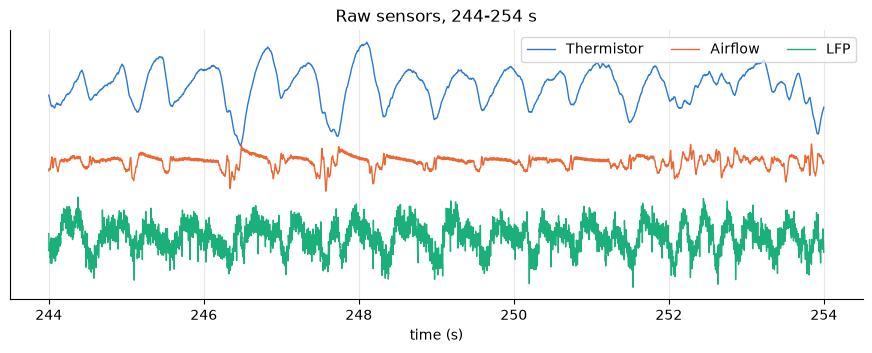

In [34]:
sensors = {"Thermistor": thermistor, "Airflow": airflow, "LFP": lfp}
zscore = lambda x: (x - x.mean()) / x.std()

# Whole recording, stacked. Good for spotting flat stretches, bursts and movement.
fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
for ax, (name, x) in zip(axes, sensors.items()):
    ax.plot(t, zscore(x), color=COLORS[name], lw=0.3)
    ax.set_ylabel(name)
    ax.set_ylim(-6, 6)           # clip huge spikes so they don't flatten everything else
axes[3].plot(t, zscore(emg), color="0.3", lw=0.3)
axes[3].set_ylabel("EMG")
axes[3].set_xlabel("time (s)")
for ax in axes:                  # mark where the video starts and ends
    ax.axvline(cam_times[0], color="gray", ls="--", lw=0.8)
    ax.axvline(cam_times[-1], color="gray", ls="--", lw=0.8)
axes[0].set_title("Whole session (dashed lines = video start and end)")
plt.tight_layout()
plt.show()

def plot_window(data, start, length=10, title=""):
    i0, i1 = int(start * FS), int((start + length) * FS)
    plt.figure()
    for k, (name, x) in enumerate(data.items()):
        plt.plot(t[i0:i1], zscore(x)[i0:i1] - 5 * k, color=COLORS[name], lw=1, label=name)
    plt.yticks([]); plt.xlabel("time (s)"); plt.title(title); plt.legend(loc="upper right", ncol=3)
    plt.show()

start = 244          # try 90 to see a messy stretch
plot_window(sensors, start, title=f"Raw sensors, {start}-{start+10} s")

### 4b. How long should each window be?

To find the stretches where the sensors agree, we score short windows. With too few breaths per window, two unrelated signals can look in step by chance. To measure that chance level, compare the thermistor with the airflow shifted by 60 s, which can't genuinely be in step.

For a shorter explanation: 5 seconds is about 10 breaths; enough that two sensors can't line up by chance, yet short enough to capture brief signal collapses. The results looks the same over the 3-10 second range. 

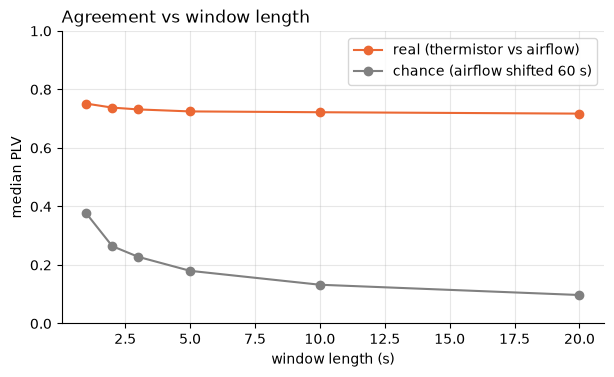

  1 s window: real 0.75   chance 0.38
  2 s window: real 0.74   chance 0.26
  3 s window: real 0.73   chance 0.23
  5 s window: real 0.72   chance 0.18
 10 s window: real 0.72   chance 0.13
 20 s window: real 0.72   chance 0.10


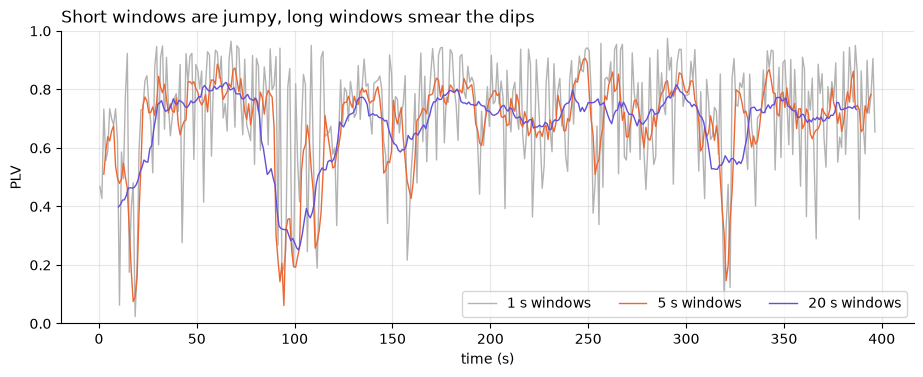

In [35]:
p_th = get_phase(thermistor)
p_af = get_phase(airflow)
p_af_shifted = np.roll(p_af, 60 * FS)        # airflow from 60 s later: unrelated by construction

wins = [1, 2, 3, 5, 10, 20]
real   = [np.median(sliding_plv(p_th, p_af,         w)[1]) for w in wins]
chance = [np.median(sliding_plv(p_th, p_af_shifted, w)[1]) for w in wins]

plt.figure(figsize=(7, 3.8))
plt.plot(wins, real, "o-", color=COLORS["Airflow"], label="real (thermistor vs airflow)")
plt.plot(wins, chance, "o-", color="0.5", label="chance (airflow shifted 60 s)")
plt.xlabel("window length (s)"); plt.ylabel("median PLV"); plt.ylim(0, 1); plt.legend()
plt.title("Agreement vs window length", loc="left"); plt.show()
for w, r, c in zip(wins, real, chance):
    print(f"{w:>3} s window: real {r:.2f}   chance {c:.2f}")

# the same comparison over time, three window lengths
fig, ax = plt.subplots(figsize=(11, 3.8))
for w, col in [(1, "0.7"), (5, COLORS["Airflow"]), (20, "#6250d6")]:
    centers, vals = sliding_plv(p_th, p_af, w)
    ax.plot(centers, vals, color=col, lw=1, label=f"{w} s windows")
ax.set_ylim(0, 1); ax.set_xlabel("time (s)"); ax.set_ylabel("PLV"); ax.legend(ncol=3, loc="lower right")
ax.set_title("Short windows are jumpy, long windows smear the dips", loc="left"); plt.show()

**Result:** chance agreement rises as windows shrink (about 0.38 at 1 s vs 0.18 at 5 s). 1-s windows are jumpy; 20-s windows smear out short dips. **We use 5 s**: a reasonable trade-off, not an optimum (3–10 s gives the same conclusions). It also matches the README's 5-s sleep-staging epochs.

### 4c. Choosing the clean and messy example windows

A window counts as **clean only if all three sensor pairs agree**, so we score each window by its *weakest* pair. (Ranking by thermistor–airflow alone ignores the LFP.)

Cleanest 5-s windows (all three pairs agree):
  starts at   295 s   th-af 0.85  th-LFP 0.88  af-LFP 0.66
  starts at    28 s   th-af 0.84  th-LFP 0.70  af-LFP 0.65
  starts at    66 s   th-af 0.87  th-LFP 0.80  af-LFP 0.64
  starts at     2 s   th-af 0.64  th-LFP 0.80  af-LFP 0.61
  starts at    44 s   th-af 0.83  th-LFP 0.78  af-LFP 0.61
Messiest 5-s windows:
  starts at   159 s   th-af 0.57  th-LFP 0.42  af-LFP 0.03
  starts at   117 s   th-af 0.53  th-LFP 0.49  af-LFP 0.04
  starts at    16 s   th-af 0.09  th-LFP 0.29  af-LFP 0.04
  starts at   251 s   th-af 0.51  th-LFP 0.33  af-LFP 0.05
  starts at    91 s   th-af 0.21  th-LFP 0.06  af-LFP 0.13


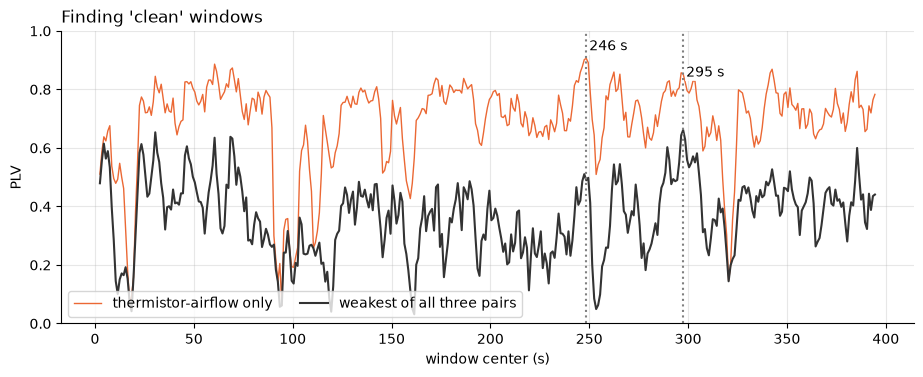

In [46]:
p_lfp = get_phase(lfp)
centers, ta = sliding_plv(p_th, p_af)
_, tl = sliding_plv(p_th, p_lfp)
_, al = sliding_plv(p_af, p_lfp)
weakest = np.minimum(np.minimum(ta, tl), al)
window_starts = centers - 2.5

def top_windows(scores, times, n=5, highest=True, min_gap=10):
    # neighboring windows overlap, so skip any within min_gap seconds of one already picked
    order = np.argsort(scores)[::-1] if highest else np.argsort(scores)
    picked = []
    for i in order:
        if all(abs(times[i] - times[j]) >= min_gap for j in picked):
            picked.append(i)
        if len(picked) == n:
            break
    return picked

print("Cleanest 5-s windows (all three pairs agree):")
for i in top_windows(weakest, window_starts):
    print(f"  starts at {window_starts[i]:5.0f} s   th-af {ta[i]:.2f}  th-LFP {tl[i]:.2f}  af-LFP {al[i]:.2f}")
print("Messiest 5-s windows:")
for i in top_windows(weakest, window_starts, highest=False):
    print(f"  starts at {window_starts[i]:5.0f} s   th-af {ta[i]:.2f}  th-LFP {tl[i]:.2f}  af-LFP {al[i]:.2f}")

# compare with the thermistor-airflow-only ranking
plt.figure(figsize=(11, 3.8))
plt.plot(centers, ta, color=COLORS["Airflow"], lw=1, label="thermistor-airflow only")
plt.plot(centers, weakest, color="0.2", lw=1.5, label="weakest of all three pairs")
for s, lab, y in [(246, "246 s", 0.97), (295, "295 s", 0.88)]:
    plt.axvline(s + 2.5, color="0.5", ls=":")
    plt.text(s + 4, y, lab, fontsize=10, va="top",
             bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
plt.ylim(0, 1); plt.xlabel("window center (s)"); plt.ylabel("PLV"); plt.legend(loc="lower left", ncol=2)
plt.title("Finding 'clean' windows", loc="left"); plt.show()

best_start  = window_starts[top_windows(weakest, window_starts, n=1)[0]]
worst_start = window_starts[top_windows(weakest, window_starts, n=1, highest=False)[0]]

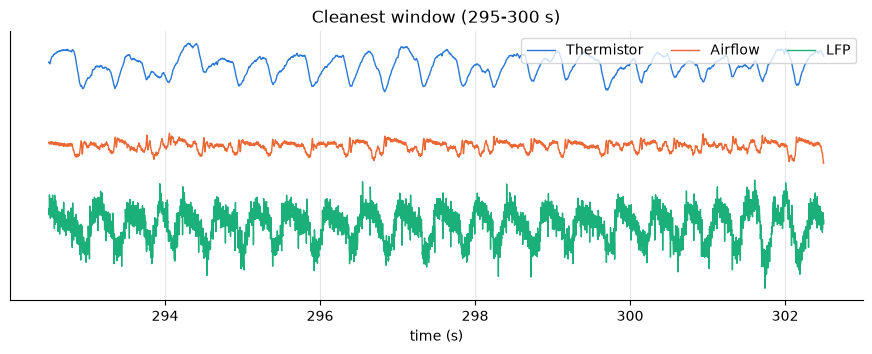

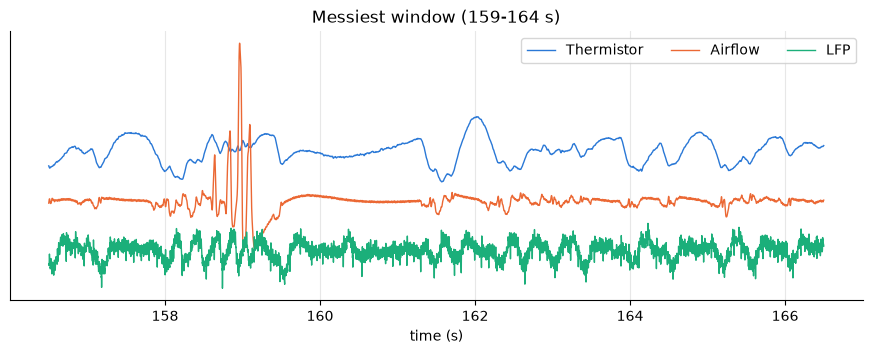

In [47]:
# 10-s views centered on the chosen 5-s windows
start = best_start - 2.5            # also used in section 6
plot_window(sensors, start, title=f"Cleanest window ({best_start:.0f}-{best_start+5:.0f} s)")
plot_window(sensors, worst_start - 2.5, title=f"Messiest window ({worst_start:.0f}-{worst_start+5:.0f} s)")

**Result:** 246 s has the best thermistor–airflow agreement, but the LFP agrees poorly there. **295–300 s is the cleanest window for all three sensors**, so that's our clean example. 

Note: these windows are *illustrations*, picked because they're extreme; the typical case is in between (section 7).

## 5. Frequency content (power spectrum)

A power spectrum shows how much of the signal sits at each frequency. Mouse breathing at rest is around **1–4 Hz**, so a clean breathing sensor should have one peak there.

- The thermistor and LFP peak near 2 Hz, as expected.
- The airflow is spread across many frequencies: its sharp spikes contain lots of high-frequency power.

### Choosing the chunk length

Welch averages spectra from many chunks. Longer chunks give finer frequency detail but fewer chunks to average, so a noisier curve.

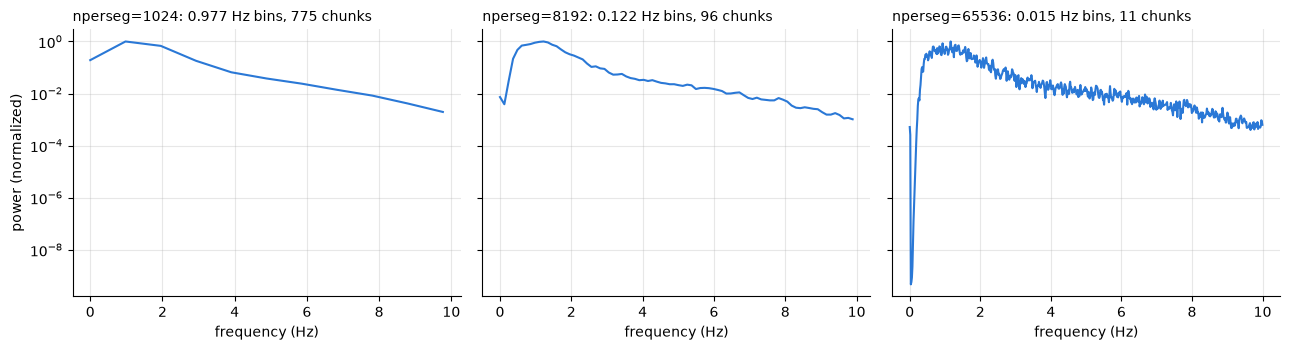

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, nps in zip(axes, [1024, 8192, 65536]):
    f, p = signal.welch(thermistor, FS, nperseg=nps)
    keep = f < 10
    ax.semilogy(f[keep], p[keep] / p[keep].max(), color=COLORS["Thermistor"])
    n_chunks = (len(thermistor) - nps // 2) // (nps // 2)
    ax.set_title(f"nperseg={nps}: {FS/nps:.3f} Hz bins, {n_chunks} chunks", loc="left", fontsize=10)
    ax.set_xlabel("frequency (Hz)")
axes[0].set_ylabel("power (normalized)"); plt.tight_layout(); plt.show()

**Result:** 1,024 is too coarse (about 1 Hz bins) to locate the breathing peak; 65,536 is jagged (only 11 chunks). **We use 8,192**: 0.12 Hz bins with 96 chunks. A sensible middle, not an optimum.

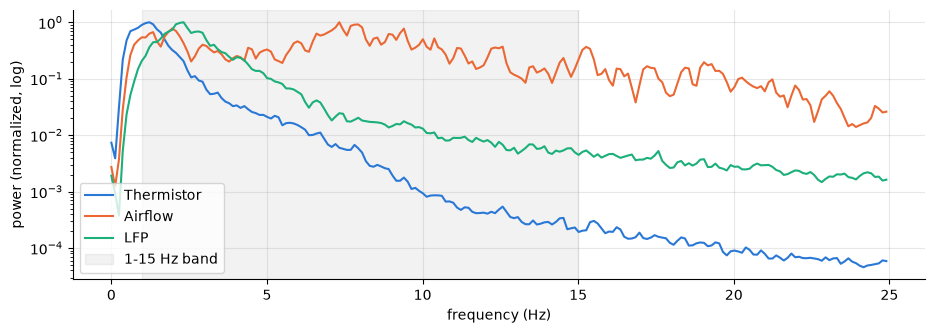

Thermistor peak at 1.22 Hz | 2 Hz: 0.3230  5 Hz: 0.0210  10 Hz: 0.0009  15 Hz: 0.0002
Airflow    peak at 7.32 Hz | 2 Hz: 0.7743  5 Hz: 0.3293  10 Hz: 0.5001  15 Hz: 0.2201
LFP        peak at 2.32 Hz | 2 Hz: 0.7335  5 Hz: 0.1022  10 Hz: 0.0130  15 Hz: 0.0045


In [49]:
plt.figure()
for name, x in sensors.items():
    f, p = signal.welch(x, FS, nperseg=8192)        # Welch = average spectrum over many short windows
    keep = f < 25
    plt.semilogy(f[keep], p[keep] / p[keep].max(), color=COLORS[name], label=name)
plt.axvspan(1, 15, color="gray", alpha=0.1, label="1-15 Hz band")
plt.xlabel("frequency (Hz)"); plt.ylabel("power (normalized, log)"); plt.legend(); plt.show()

for name, x in sensors.items():
    f, p = signal.welch(x, FS, nperseg=8192)
    keep = f < 25
    p_norm = p / p[keep].max()                        # same normalization as the plot
    peak = f[keep][np.argmax(p[keep])]
    values = "  ".join(f"{fr} Hz: {p_norm[np.argmin(abs(f - fr))]:.4f}" for fr in [2, 5, 10, 15])
    print(f"{name:10s} peak at {peak:.2f} Hz | {values}")

## 6. From signal to phase

**Phase** says *where in the breath cycle* we are, as an angle from −π to π. It wraps around once per breath, so it ignores how big the signal is and keeps only the timing. That makes sensors with different units directly comparable.

Two steps:
1. **Band-pass filter** to keep only breathing frequencies (here 1–15 Hz). `filtfilt` runs the filter forward and backward, so it adds no time delay.
2. **Hilbert transform.** It turns the real signal into a complex one, $x(t) + i\,\mathcal{H}[x](t)$, a point rotating around the origin. The angle of that point is the phase. (Think of $\cos\theta$ → $e^{i\theta}$.)

### 6a. Which filter band?

The PI suggested 1–15 Hz. Before using it, check how the band affects agreement between sensors.

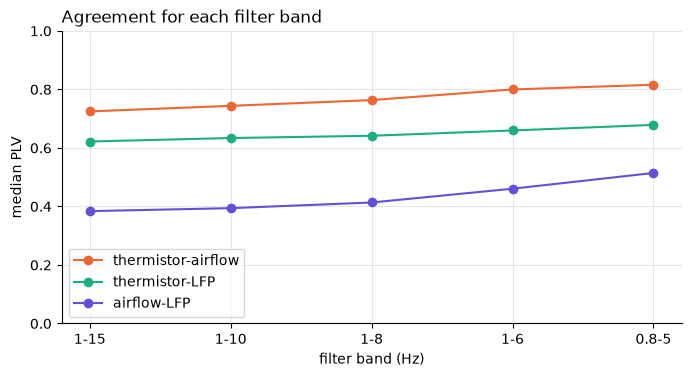

thermistor-airflow   1-15: 0.72  1-10: 0.74  1-8: 0.76  1-6: 0.80  0.8-5: 0.82
thermistor-LFP       1-15: 0.62  1-10: 0.63  1-8: 0.64  1-6: 0.66  0.8-5: 0.68
airflow-LFP          1-15: 0.38  1-10: 0.39  1-8: 0.41  1-6: 0.46  0.8-5: 0.51


In [50]:
bands = [(1, 15), (1, 10), (1, 8), (1, 6), (0.8, 5)]
pairs = {"thermistor-airflow": (thermistor, airflow),
         "thermistor-LFP":     (thermistor, lfp),
         "airflow-LFP":        (airflow, lfp)}
table = {name: [] for name in pairs}
for lo, hi in bands:
    for name, (x1, x2) in pairs.items():
        table[name].append(np.median(sliding_plv(get_phase(x1, lo, hi), get_phase(x2, lo, hi))[1]))

labels = [f"{lo}-{hi}" for lo, hi in bands]
plt.figure(figsize=(8, 3.8))
for (name, vals), col in zip(table.items(), [COLORS["Airflow"], COLORS["LFP"], "#6250d6"]):
    plt.plot(labels, vals, "o-", color=col, label=name)
plt.xlabel("filter band (Hz)"); plt.ylabel("median PLV"); plt.ylim(0, 1); plt.legend()
plt.title("Agreement for each filter band", loc="left"); plt.show()
for name, vals in table.items():
    print(f"{name:20s}", "  ".join(f"{l}: {v:.2f}" for l, v in zip(labels, vals)))

**Result:** every pair agrees more as the band narrows, so much of the 5–15 Hz content isn't shared between sensors. But higher agreement isn't automatically better: a narrow band also removes real fast breathing such as sniffing (6–12 Hz). **Keep recommended 1-15Hz** and raise the band as a question.

### 6b. Why filter forward *and* backward?

A normal filter runs forward through time and shifts the signal. Test it on a clean 2 Hz wave.

In [1]:
tt = np.arange(0, 3, 1 / FS)
wave = np.sin(2 * np.pi * 2 * tt)
b, a = signal.butter(3, [1, 15], btype="band", fs=FS)
one_way = signal.lfilter(b, a, wave)        # forward only
two_way = signal.filtfilt(b, a, wave)       # forward + backward

m = (tt > 1) & (tt < 2.5)
plt.plot(tt[m], wave[m], color="0.3", lw=3, alpha=0.4, label="original")
plt.plot(tt[m], two_way[m], color=COLORS["LFP"], label="filtfilt (forward + backward)")
plt.plot(tt[m], one_way[m], color=COLORS["Airflow"], ls="--", label="lfilter (forward only)")
plt.legend(loc="upper right"); plt.xlabel("time (s)")
plt.title("Effect of filtering on timing", loc="left"); plt.show()

lag = signal.correlation_lags(len(wave), len(wave))[np.argmax(signal.correlate(one_way, wave))]
print(f"forward-only filter shifts the wave by about {abs(lag)} ms; filtfilt shifts it by 0 ms")

NameError: name 'np' is not defined

**Result:** the forward-only filter shifts the wave; `filtfilt` lines up with the original. The shift depends on frequency, and each sensor has a different mix of frequencies, so a one-way filter would shift each sensor differently. Since we compare timing across sensors, **`filtfilt` is required**. (Small mismatches at the very edge are edge effects; all filters misbehave at the start and end of a recording.)

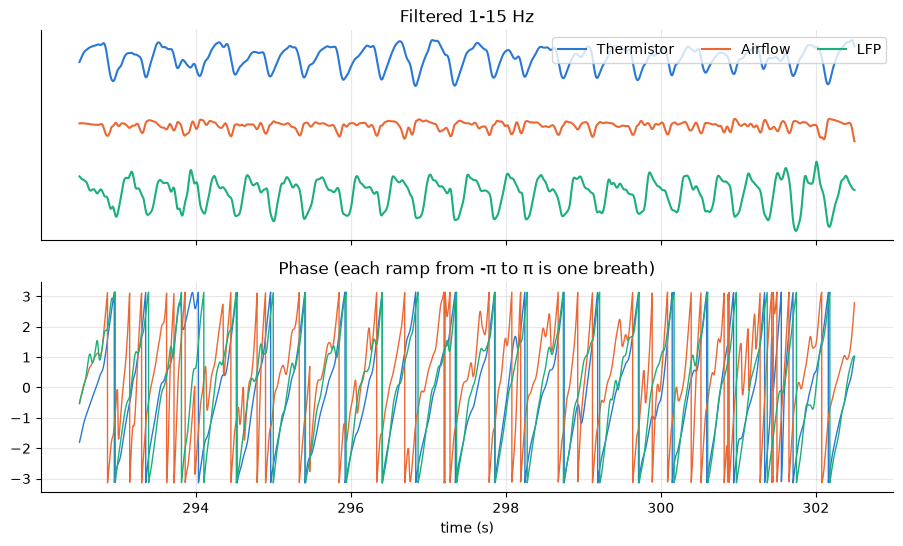

In [ ]:
def bandpass(x, lo, hi, order=3):
    b, a = signal.butter(order, [lo, hi], btype="band", fs=FS)
    return signal.filtfilt(b, a, x, axis=0)

def get_phase(x, lo=1, hi=15):
    return np.angle(signal.hilbert(bandpass(x, lo, hi), axis=0))

filtered = {name: bandpass(x, 1, 15) for name, x in sensors.items()}
phase    = {name: get_phase(x)       for name, x in sensors.items()}

i0, i1 = int(start * FS), int((start + 10) * FS)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for k, name in enumerate(sensors):
    axes[0].plot(t[i0:i1], zscore(filtered[name])[i0:i1] - 5 * k, color=COLORS[name], label=name)
    axes[1].plot(t[i0:i1], phase[name][i0:i1], color=COLORS[name], lw=1)
axes[0].set_title("Filtered 1-15 Hz"); axes[0].set_yticks([]); axes[0].legend(loc="upper right", ncol=3)
axes[1].set_title("Phase (each ramp from -π to π is one breath)"); axes[1].set_xlabel("time (s)")
plt.show()

Below are clearer comparison plots after taking the Hilbert transform of all three signals. 

Each sensor gets its own panel, and we show two different 5-second windows: a **clean stretch** (295-300s, all three sensors agree best) and a **messy stretch** (90–95 s, one of the lowest-agreement windows in the session, which includes fast breathing, a moment where all three sensors go quiet, and the start of a muscle-activity burst (EMG) at about 94 s.) 

Each diagonal ramp from -pi to pi is one cycle of the signal (a breath). 

This is a breakdown on how to read the plots;

Every peak lines up with phase = 0. Every trough lines up with a wrap(pi to -pi). 

Claude noted nuance: Look at the first peak, at 246.12 s. The dot sits a bit before the highest point of the wave (the wave keeps rising to a small plateau at about 246.2 s). Phase 0 marks the top exactly only when each wave is symmetric. When a breath is lopsided (rises slowly and falls fast, or has a bump at the top), phase 0 lands close to the top but not exactly on it. That doesn’t break anything for our purposes, since we compare phase differences, but it means “phase 0 = peak” is an approximation for real breaths.

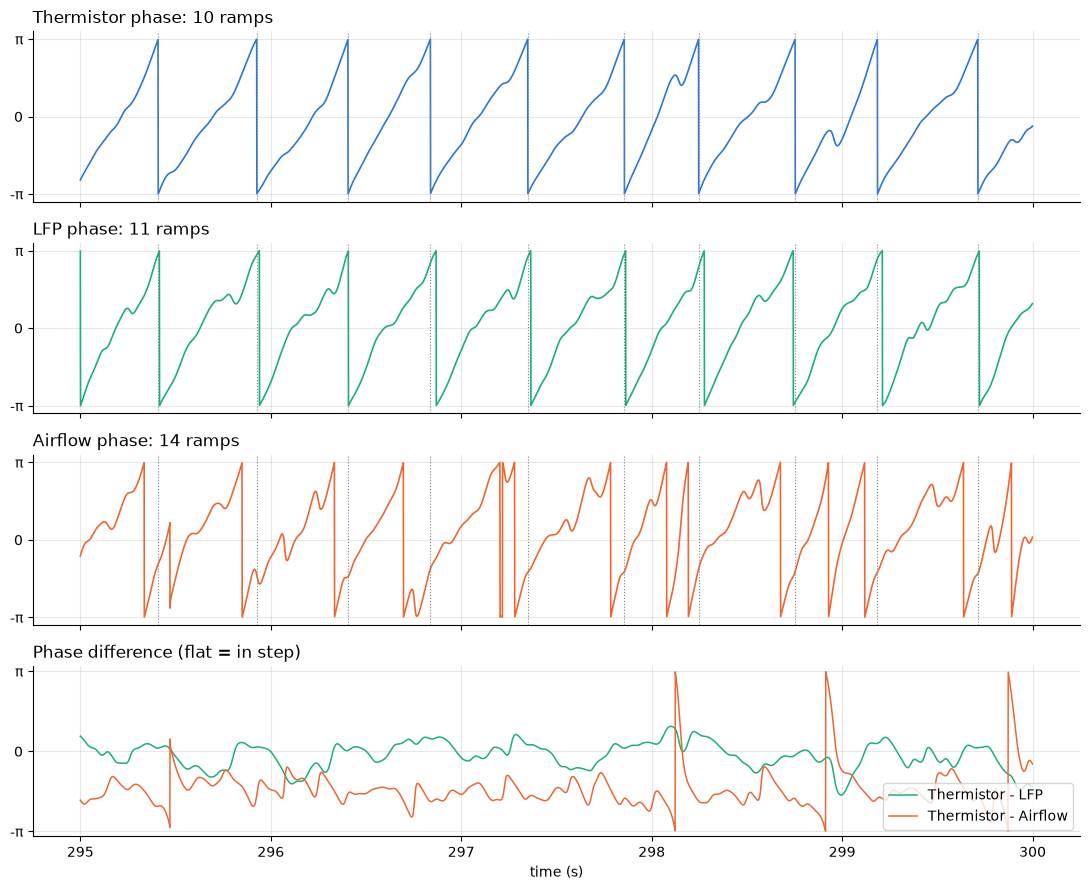

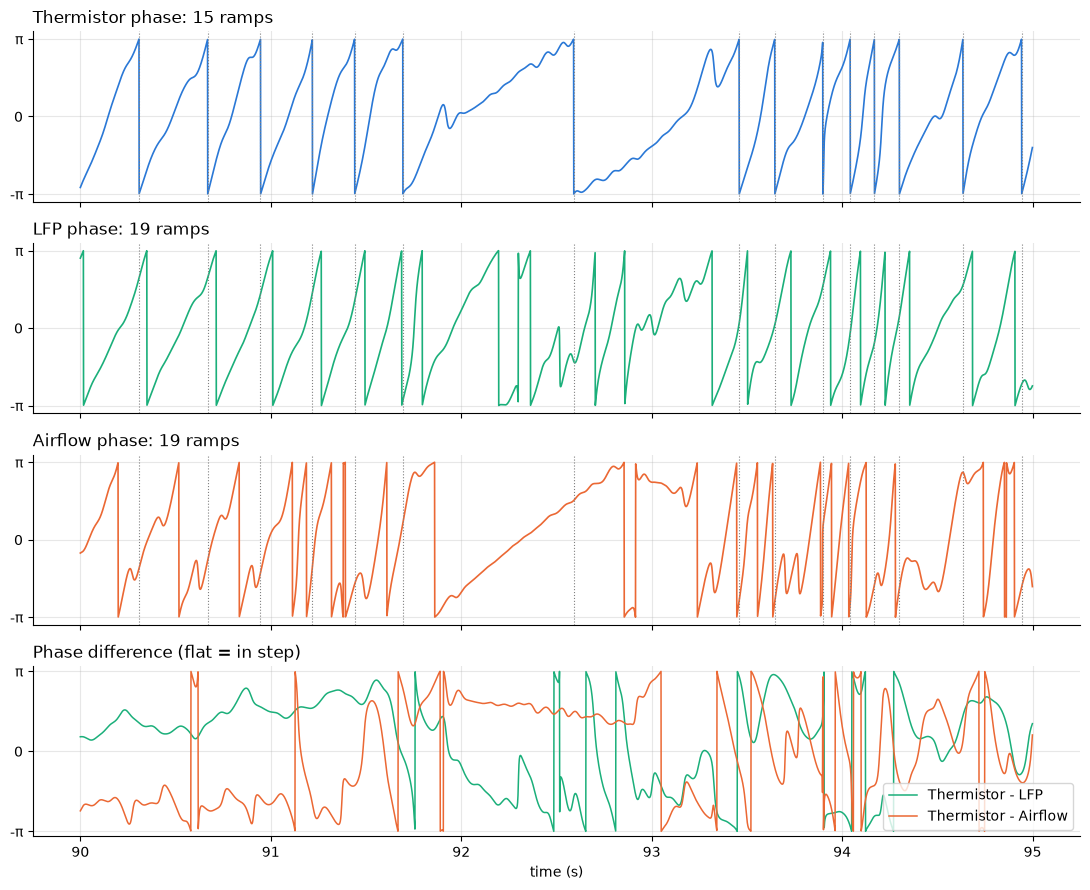

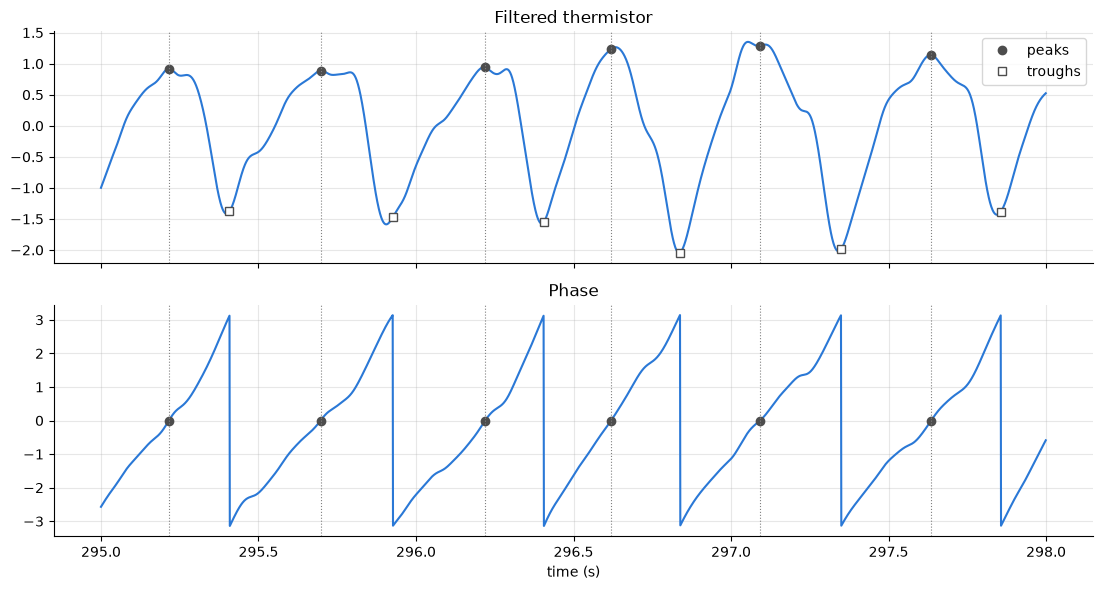

In [ ]:
def compare_phases(start, length=5):
    i0, i1 = int(start * FS), int((start + length) * FS)
    tt = t[i0:i1]
    th_breaths = np.where(np.diff(phase["Thermistor"][i0:i1]) < -np.pi)[0]   # thermistor wraps

    fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
    for ax, name in zip(axes[:3], ["Thermistor", "LFP", "Airflow"]):
        p = phase[name][i0:i1]
        n_ramps = round((np.unwrap(p)[-1] - np.unwrap(p)[0]) / (2 * np.pi))
        ax.plot(tt, p, color=COLORS[name], lw=1.2)
        ax.set_title(f"{name} phase: {n_ramps} ramps", loc="left")
        ax.set_yticks([-np.pi, 0, np.pi]); ax.set_yticklabels(["-π", "0", "π"])
        for i in th_breaths:
            ax.axvline(tt[i], color="gray", ls=":", lw=0.8)

    # phase difference, wrapped back into [-π, π]
    for name in ["LFP", "Airflow"]:
        diff = np.angle(np.exp(1j * (phase["Thermistor"][i0:i1] - phase[name][i0:i1])))
        axes[3].plot(tt, diff, color=COLORS[name], lw=1.1, label=f"Thermistor - {name}")
    axes[3].set_ylim(-np.pi - 0.2, np.pi + 0.2)
    axes[3].set_yticks([-np.pi, 0, np.pi]); axes[3].set_yticklabels(["-π", "0", "π"])
    axes[3].set_title("Phase difference (flat = in step)", loc="left")
    axes[3].legend(loc="lower right"); axes[3].set_xlabel("time (s)")
    plt.tight_layout(); plt.show()

compare_phases(295)   #clean
compare_phases(90)    # messy


peak_start, peak_length = 295, 3
i0, i1 = int(peak_start * FS), int((peak_start + peak_length) * FS)
tt = t[i0:i1]
wave = zscore(filtered["Thermistor"])[i0:i1]
ph = phase["Thermistor"][i0:i1]

peaks   = np.where((ph[:-1] < 0) & (ph[1:] >= 0))[0]     # phase crosses 0 going up -> peak
troughs = np.where(np.diff(ph) < -np.pi)[0]              # phase wraps from π to -π -> trough

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(tt, wave, color=COLORS["Thermistor"])
axes[0].plot(tt[peaks], wave[peaks], "o", color="0.3", label="peaks")
axes[0].plot(tt[troughs], wave[troughs], "s", color="0.3", mfc="white", label="troughs")
axes[0].legend(loc="upper right"); axes[0].set_title("Filtered thermistor")
axes[1].plot(tt, ph, color=COLORS["Thermistor"])
axes[1].plot(tt[peaks], ph[peaks], "o", color="0.3")
axes[1].set_title("Phase"); axes[1].set_xlabel("time (s)")
for i in peaks:
    for ax in axes:
        ax.axvline(tt[i], color="gray", ls=":", lw=0.8)
plt.tight_layout(); plt.show()

**Results**

In the **clean window**, LFP ramp restarts almost exactly on the dotted line(start of a thermistor breath), meaning the LFP and thermistor agree during clean windows. Whereas for airflow. most ramps start just before the dotted line consistently, which reflects the same fact as earlier: airflow responds before the slower thermistor and LFP, with some extra cycle ramps squeezed in. 

The phase difference:

    Therm-LFP(green) - flat, and hovering around 0, signaling close agreement and barely any lag amongst the two signals.

    Therm-airflow(orange) - mostly flat around -1.3(a fifth of a cycle), in step with same lag we observed. There are also four spikes which line up with the extra ramps in airflow before realigning. 

Intepretation: In a clean stretch, all three sensors track the same breathing cycle except airflow which tracks a few extra cycles. 

In the **messy** window, we see more cycles per second in both the thermistor and LFP, each increasing by 1. The LFP restarts near the dotted line and the phase difference stays fairly flat around0.3-0.9 (eyeball value), meaning the thermistor and LFP agree and the mouse most likely is breathing faster. Airflow is 
    
    Signal Loss: around 92-93.5, the thermistor shows two longs ramps around a second each and airflow only shows one. These are where the signal went flat. LFP is jitery here and loses phase agreement with thermistor. 
    
    After 93.4, we observe EMG rise around 94s, signaling muscle activity. The thermistor becomes short and irregular, LFP and airflow both show an increase in cycles and both difference lines are all over the place. This means that there is no consistent relationship. 
    
    Note: This is where we need to decide how to model breath to with the signals that we have. 



## 7. How well do two sensors agree? (phase-locking value)

If two sensors track the same breathing, their **phase difference** stays roughly constant (one may lag the other, but by a steady amount).

The **phase-locking value (PLV)** measures that steadiness:

$$\text{PLV} = \left|\frac{1}{N}\sum_{n} e^{\,i(\phi_1[n]-\phi_2[n])}\right|$$

Each sample's phase difference is a unit arrow. If the arrows all point the same way, their average has length 1 (perfect agreement); if they point every which way, they cancel out to near 0.

We compute PLV in 5-second windows sliding through the recording, and plot EMG (muscle activity) underneath as a stand-in for movement.

### 7a. What does EMG smoothing hide?

The plot below smooths EMG over 5 s, the same as the PLV windows. That spreads any short burst over 5 seconds. Before using it as a movement indicator, look at 85–100 s at 0.25-s resolution, next to the strength (amplitude) of each breathing signal. Amplitude is the distance of the Hilbert point from the center of the circle.

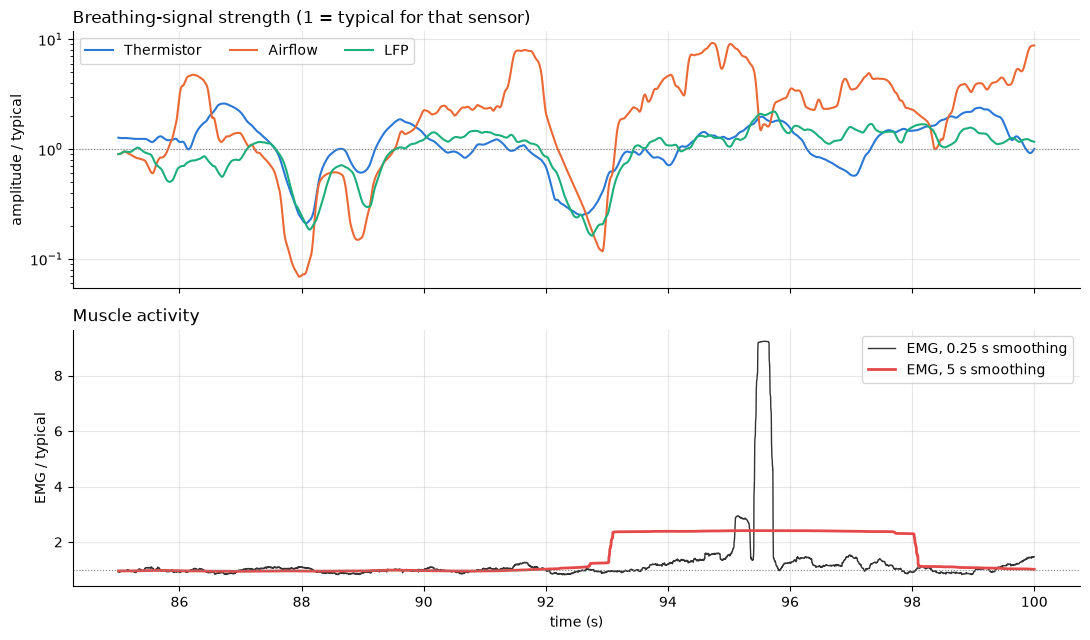

 time   therm  airflow   LFP   EMG(0.25 s)
 88.0    0.23    0.07    0.25     1.09
 88.5    0.92    0.61    0.63     0.89
 89.0    0.61    0.16    0.33     0.88
 89.5    1.70    0.95    0.97     1.00
 90.0    1.38    2.25    1.22     1.00
 90.5    0.95    2.03    1.28     0.96
 91.0    1.10    2.34    1.43     1.03
 91.5    0.99    7.66    1.22     1.18
 92.0    0.69    2.16    0.85     0.97
 92.5    0.26    0.41    0.24     0.94
 93.0    0.54    0.30    0.25     0.93
 93.5    0.91    2.31    1.08     0.99
 94.0    0.72    4.62    1.08     1.20
 94.5    1.34    7.28    1.31     1.32
 95.0    1.23    8.85    1.05     1.53
 95.5    1.94    1.64    2.08     9.20
 96.0    1.56    3.49    1.42     1.27
 96.5    0.84    2.66    1.27     1.11
 97.0    0.58    3.51    1.59     1.51
 97.5    1.38    4.37    1.42     1.33
 98.0    1.47    2.29    1.58     0.91


In [57]:
emg_hf     = bandpass(emg, 30, 300)                 # muscle activity lives at high frequencies
emg_fine   = np.sqrt(smooth(emg_hf**2, 0.25))
emg_coarse = np.sqrt(smooth(emg_hf**2, 5))

amp = {name: smooth(np.abs(signal.hilbert(bandpass(x, 1, 15))), 0.5)
       for name, x in [("Thermistor", thermistor), ("Airflow", airflow), ("LFP", lfp)]}

i0, i1 = 85 * FS, 100 * FS
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for name, a_ in amp.items():
    axes[0].plot(t[i0:i1], a_[i0:i1] / np.median(a_), color=COLORS[name], label=name)
axes[0].axhline(1, color="0.5", lw=0.8, ls=":")
axes[0].set_yscale("log"); axes[0].set_ylabel("amplitude / typical")
axes[0].set_title("Breathing-signal strength (1 = typical for that sensor)", loc="left"); axes[0].legend(ncol=3)
axes[1].plot(t[i0:i1], emg_fine[i0:i1] / np.median(emg_fine), color="0.2", lw=1, label="EMG, 0.25 s smoothing")
axes[1].plot(t[i0:i1], emg_coarse[i0:i1] / np.median(emg_coarse), color="#e34948", lw=2, label="EMG, 5 s smoothing")
axes[1].axhline(1, color="0.5", lw=0.8, ls=":")
axes[1].set_ylabel("EMG / typical"); axes[1].set_xlabel("time (s)"); axes[1].legend()
axes[1].set_title("Muscle activity", loc="left")
plt.tight_layout(); plt.show()

print(" time   therm  airflow   LFP   EMG(0.25 s)")
for s in np.arange(88, 98.5, 0.5):
    i = int(s * FS)
    print(f"{s:5.1f}  " + "  ".join(f"{amp[n][i] / np.median(amp[n]):6.2f}" for n in amp)
          + f"   {emg_fine[i] / np.median(emg_fine):6.2f}")

**Result:**
- At fine resolution, the EMG stays typical until about 94 s, rises mildly from 94 to 97 s, and has one sharp burst at about 95.5 s. The 5-s smoothing (red) spreads that burst into a broad block, so the overview suggests movement across the whole stretch.
- Around 92.5–93 s (and about 88 s), **all three breathing signals drop to roughly a quarter of their usual strength together** while the EMG stays typical. Three independent sensors going quiet at once is more consistent with a real pause in breathing than with three sensor failures.
- Limits: "no muscle activity" means none on this EMG electrode, whose location we don't know; the video would confirm. The 95.5 s burst lines up with the LFP's artifact burst.

We keep 5-s smoothing in the overview below (it matches the PLV windows), but read its EMG bumps as "something happened in this 5-s span," not as how long it lasted.

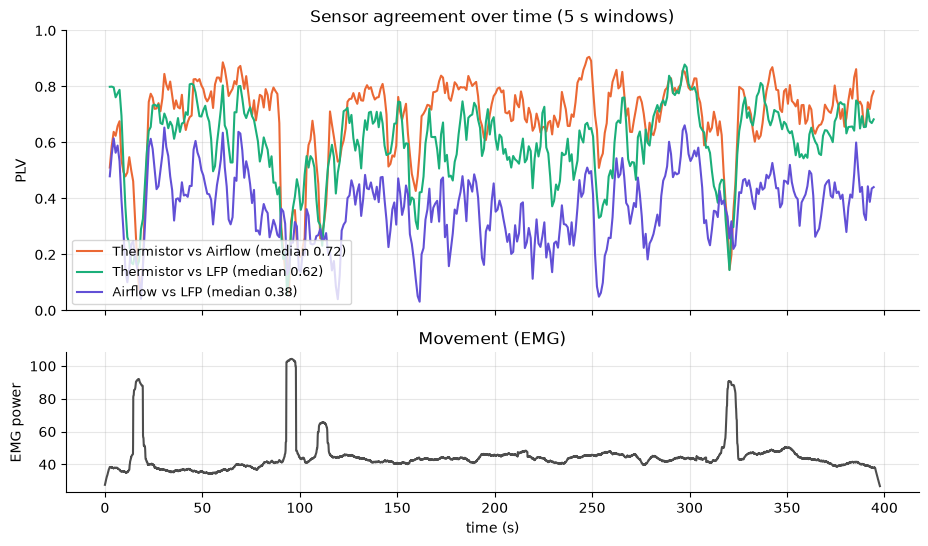

In [58]:
def plv(p1, p2):
    return np.abs(np.mean(np.exp(1j * (p1 - p2))))

def sliding_plv(p1, p2, win_s=5, step_s=1):
    W, S = int(win_s * FS), int(step_s * FS)
    starts = np.arange(0, len(p1) - W, S)
    return (starts + W / 2) / FS, np.array([plv(p1[s:s+W], p2[s:s+W]) for s in starts])

pairs = [("Thermistor", "Airflow"), ("Thermistor", "LFP"), ("Airflow", "LFP")]
pair_colors = ["#eb6834", "#1baf7a", "#6250d6"]

# movement proxy: EMG filtered to muscle frequencies, then its smoothed power
emg_hf = bandpass(emg, 30, 300)
emg_power = np.sqrt(np.convolve(emg_hf**2, np.ones(5 * FS) / (5 * FS), mode="same"))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for (a, b), c in zip(pairs, pair_colors):
    centers, values = sliding_plv(phase[a], phase[b])
    axes[0].plot(centers, values, color=c, label=f"{a} vs {b} (median {np.median(values):.2f})")
axes[0].set_ylim(0, 1); axes[0].set_ylabel("PLV"); axes[0].legend(loc="lower left", fontsize=9)
axes[0].set_title("Sensor agreement over time (5 s windows)")
axes[1].plot(t[::50], emg_power[::50], color="0.3"); axes[1].set_ylabel("EMG power")
axes[1].set_xlabel("time (s)"); axes[1].set_title("Movement (EMG)")
plt.show()

**What to notice:** agreement drops sharply near the EMG bumps (≈18, 95, 320 s). Not every drop is movement: around 92.5–93 s the sensors go quiet together with typical muscle activity (7a).